# LR 2.2: replication of group draft
rebuild the draft's dataset from `HIT140_Assess_3_code_and_datasets/uefa/data/` and test its claims

In [1]:
import math
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.stats as st
import seaborn as sns
import statsmodels.api as sm
from sklearn import metrics
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PowerTransformer, StandardScaler

RAW = Path("../../HIT140_Assess_3_code_and_datasets/uefa/data")
OUT = Path("results")
FIG = Path("figures")
OUT.mkdir(parents=True, exist_ok=True)

TEST_SIZE = 0.2
RANDOM_STATE = 42
BLUE, ORANGE, INK = "#2a78d6", "#eb6834", "#222222"
pd.set_option("display.width", 200)

## 1. build dataset
208 team-match rows, the draft's 8 predictors. prior = mean of the team's earlier matches (NaN for a first match). drop the stray GHA/uzbekistan row in `external.csv`.

In [2]:
matches = pd.read_csv(RAW / "matches.csv")
mt = pd.read_csv(RAW / "match_teams.csv")
att = pd.read_csv(RAW / "attempts_at_goal.csv")
lb = pd.read_csv(RAW / "player_line_breaks.csv")
ext = pd.read_csv(RAW / "external.csv")
ext = ext[~((ext["team_id"] == "GHA") & (ext["team_name"] == "Uzbekistan"))]   # duplicate row

# one row per team per match, with the match number and goals scored
tm = pd.merge(mt, matches[["match_id", "match_number"]], on="match_id")
tm["goals"] = tm["score"]

# goals conceded = the opponent's score in the same match
opp_score = tm[["match_id", "team_id", "score"]].rename(columns={"team_id": "opp_id", "score": "goals_against"})
tm = pd.merge(tm, opp_score, on="match_id")
tm = tm[tm["team_id"] != tm["opp_id"]]

# per-match totals: shots (all outcomes) and line breaks attempted
tm = tm.join(att.groupby("match_team_id").size().rename("attempts"), on="match_team_id")
tm = tm.join(lb.groupby("match_team_id")["line_breaks_attempted"].sum().rename("lb_att"), on="match_team_id")
tm["attempts"] = tm["attempts"].fillna(0)
tm["lb_att"] = tm["lb_att"].fillna(0)

# "prior" = mean over the same team's earlier matches only (empty for a first match -> NaN)
for c in ["goals", "goals_against", "attempts", "lb_att"]:
    tm[c + "_prior"] = tm.apply(
        lambda row: tm[(tm["team_id"] == row["team_id"]) & (tm["match_number"] < row["match_number"])][c].mean(), axis=1)

# pre-tournament team data
tm = pd.merge(tm, ext[["team_id", "elo", "squad_value_meur", "avg_player_value_meur"]], on="team_id", how="left")
tm["log_value"] = np.log(tm["squad_value_meur"])
tm["log_avg_value"] = np.log(tm["avg_player_value_meur"])
HOSTS = ["Mexico", "Canada", "United States", "USA"]
tm["is_host"] = tm["team_name"].apply(lambda name: 1 if name in HOSTS else 0)

# attach the opponent's values to each row
opp_cols = ["elo", "goals_prior", "goals_against_prior", "lb_att_prior", "log_value", "log_avg_value"]
opp = tm[["match_id", "team_id"] + opp_cols].rename(columns={"team_id": "opp_id2", **{c: "opp_" + c for c in opp_cols}})
T = pd.merge(tm, opp, on="match_id")
T = T[T["team_id"] != T["opp_id2"]].copy()

T["elo_diff"] = T["elo"] - T["opp_elo"]
T["gf_prior_diff"] = T["goals_prior"] - T["opp_goals_prior"]
T["ga_prior_diff"] = T["goals_against_prior"] - T["opp_goals_against_prior"]
T["lb_prior_diff"] = T["lb_att_prior"] - T["opp_lb_att_prior"]
T["team_attempts_prior"] = T["attempts_prior"]
T["team_log_value"] = T["log_value"]

feats = ["elo_diff", "gf_prior_diff", "ga_prior_diff", "lb_prior_diff",
         "team_attempts_prior", "team_log_value", "opp_log_value", "is_host"]
T = T.rename(columns={"match_number": "match"}).sort_values(["match", "team_name"]).reset_index(drop=True)
print(T.shape[0], "rows")
T[["match", "team_name", "goals"] + feats].head()

208 rows


,match,team_name,goals,elo_diff,gf_prior_diff,ga_prior_diff,lb_prior_diff,team_attempts_prior,team_log_value,opp_log_value,is_host
0,1,Mexico,2,357,NaN,NaN,NaN,NaN,5.471430,3.884652,1
1,1,South Africa,0,-357,NaN,NaN,NaN,NaN,3.884652,5.471430,0
2,2,Czechia,1,-18,NaN,NaN,NaN,NaN,5.262172,4.907864,0
3,2,Korea Republic,2,18,NaN,NaN,NaN,NaN,4.907864,5.262172,0
4,3,Bosnia and Herzegovina,1,-193,NaN,NaN,NaN,NaN,5.080161,4.952158,0


## 2. data checks
row counts, scores agree between the two files, missing cells (draft: 192).

In [3]:
print("Rows:", T.shape[0], "| matches:", T["match"].nunique(), "| teams:", T["team_name"].nunique())

home = mt[mt["home_away"] == "home"][["match_id", "score"]].rename(columns={"score": "home_from_match_teams"})
away = mt[mt["home_away"] == "away"][["match_id", "score"]].rename(columns={"score": "away_from_match_teams"})
check = pd.merge(pd.merge(matches[["match_id", "home_score", "away_score"]], home, on="match_id"), away, on="match_id")
mismatches = check[(check["home_score"] != check["home_from_match_teams"]) | (check["away_score"] != check["away_from_match_teams"])]
print("Matches compared:", len(check), "| matches where the two files disagree:", len(mismatches))
print("Total goals:", T["goals"].sum())
print("Missing predictor cells:", T[feats].isna().sum().sum(), "(draft reports 192)")

Rows: 208 | matches: 104 | teams: 48
Matches compared: 104 | matches where the two files disagree: 0
Total goals: 308
Missing predictor cells: 192 (draft reports 192)


## 3. EDA

### 3.1 response
describe, 95% CI, histogram, boxplot, IQR outliers.

count    208.000
mean       1.481
std        1.393
min        0.000
25%        0.000
50%        1.000
75%        2.000
max        7.000
skew 1.15
95% CI for mean goals per team per match: 1.29 to 1.67


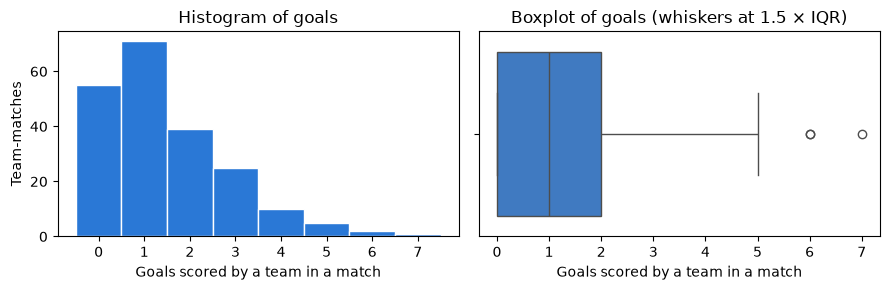

IQR outliers (goals > 5.0):


,match,team_name,goals
19,10,Germany,7
52,27,Canada,6
204,103,England,6


In [4]:
y = T["goals"]
print(y.describe().round(3).to_string())
print(f"skew {y.skew():.2f}")

z = st.norm.ppf(q=0.975)
std_err = y.std() / math.sqrt(len(y))
print(f"95% CI for mean goals per team per match: {y.mean() - z * std_err:.2f} to {y.mean() + z * std_err:.2f}")

q1, q3 = y.quantile([0.25, 0.75])
upper = q3 + 1.5 * (q3 - q1)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9, 3))
ax1.hist(y, bins=np.arange(-0.5, y.max() + 1.5, 1), color=BLUE, edgecolor="white")
ax1.set(title="Histogram of goals", xlabel="Goals scored by a team in a match", ylabel="Team-matches")
sns.boxplot(x=y, ax=ax2, color=BLUE, whis=1.5)
ax2.set(title="Boxplot of goals (whiskers at 1.5 × IQR)", xlabel="Goals scored by a team in a match")
plt.tight_layout(); plt.show()
print(f"IQR outliers (goals > {upper:.1f}):")
T[y > upper][["match", "team_name", "goals"]]

### 3.2 host flag
bar chart, boxplot + swarmplot, welch t-test.

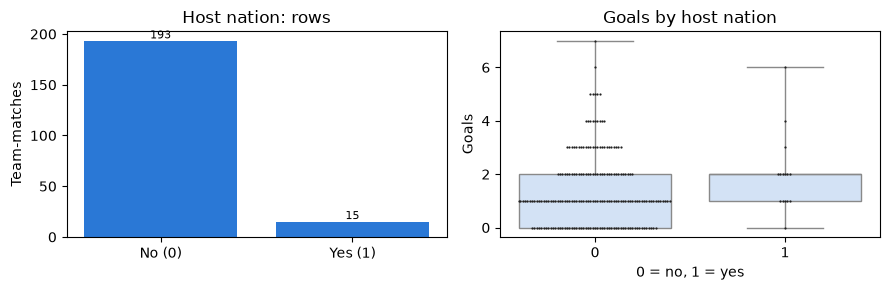

Host nations: mean goals 2.00 (n=15) vs others 1.44 (n=193); t = 1.43, p = 0.1715 -> do not reject H0 at 5%


In [5]:
fig, (axb, axs) = plt.subplots(1, 2, figsize=(9, 3))
counts = T["is_host"].value_counts().sort_index()
axb.bar(["No (0)", "Yes (1)"], counts.values, color=BLUE)
for i, v in enumerate(counts.values):
    axb.annotate(str(v), (i, v), ha="center", va="bottom", fontsize=8)
axb.set(title="Host nation: rows", ylabel="Team-matches")
sns.boxplot(x=T["is_host"], y=T["goals"], ax=axs, color="#cde2fb", whis=np.inf)
sns.swarmplot(x=T["is_host"], y=T["goals"], ax=axs, color=INK, size=1.6, warn_thresh=1)
axs.set(title="Goals by host nation", xlabel="0 = no, 1 = yes", ylabel="Goals")
plt.tight_layout(); plt.show()

g1, g0 = T[T["is_host"] == 1]["goals"], T[T["is_host"] == 0]["goals"]
t_stat, p_val = st.ttest_ind(g1, g0, equal_var=False, alternative="two-sided")
print(f"Host nations: mean goals {g1.mean():.2f} (n={len(g1)}) vs others {g0.mean():.2f} (n={len(g0)}); "
      f"t = {t_stat:.2f}, p = {p_val:.4f} -> {'reject' if p_val < 0.05 else 'do not reject'} H0 at 5%")

### 3.3 continuous predictors
scatter vs goals; pearson r, p, skew.

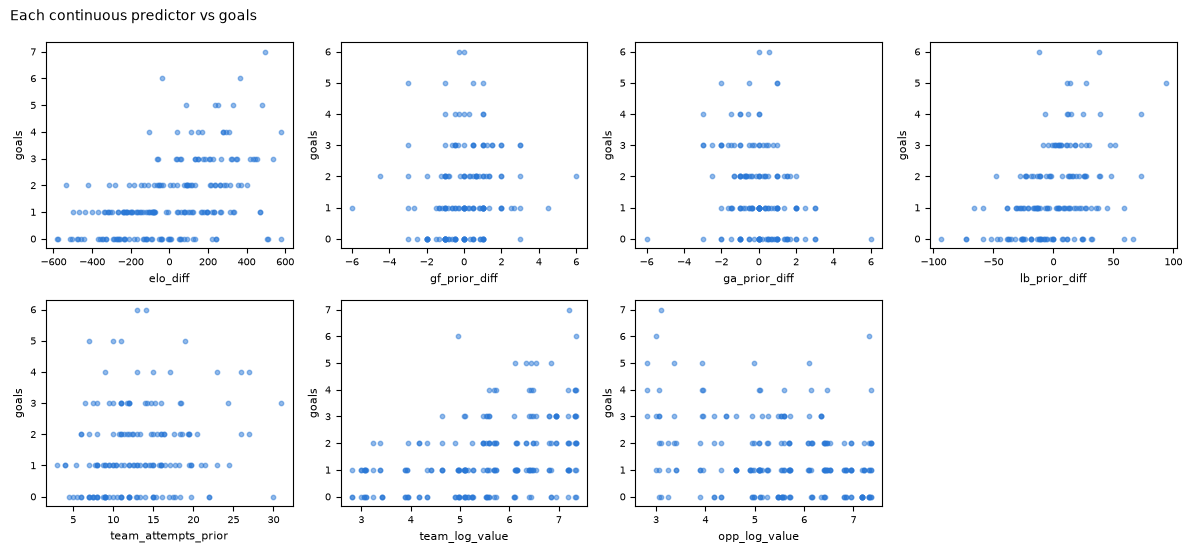

,n,r,p_value,skew
predictor,,,,
elo_diff,208,0.4885,0.0000,0.0000
team_log_value,208,0.4155,0.0000,-0.4587
lb_prior_diff,160,0.3945,0.0000,0.0000
opp_log_value,208,-0.3033,0.0000,-0.4587
ga_prior_diff,160,-0.2468,0.0017,0.0000
team_attempts_prior,160,0.1876,0.0176,0.7674
gf_prior_diff,160,0.1341,0.0908,0.0000
is_host,208,0.1041,0.1344,3.3323


In [6]:
cont = [f for f in feats if f != "is_host"]
fig, axes = plt.subplots(2, 4, figsize=(12, 5.6))
for ax, f in zip(axes.flat, cont):
    rows = T[T[f].notna()]
    ax.scatter(rows[f], rows["goals"], s=10, alpha=0.5, color=BLUE)
    ax.set_xlabel(f, fontsize=8); ax.set_ylabel("goals", fontsize=8); ax.tick_params(labelsize=7)
axes.flat[-1].set_visible(False)
fig.suptitle("Each continuous predictor vs goals", fontsize=10, x=0.01, ha="left")
plt.tight_layout(); plt.show()

rows = []
for f in feats:
    valid = T[T[f].notna()]
    r, p = st.pearsonr(valid[f], valid["goals"])
    rows.append({"predictor": f, "n": len(valid), "r": r, "p_value": p, "skew": T[f].skew()})
pearson = pd.DataFrame(rows).set_index("predictor").sort_values("r", key=abs, ascending=False).round(4)
pearson

### 3.4 multicollinearity
heatmap. drop one of a pair only if |r| ≈ 0.9.

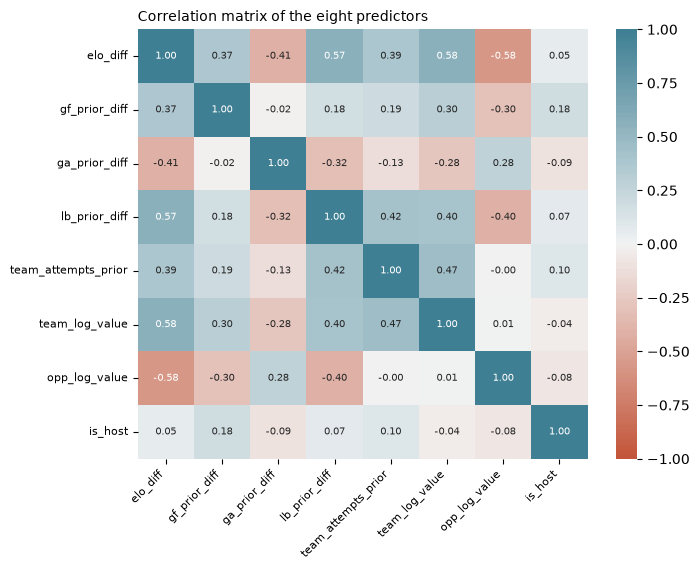

most correlated predictor pair: elo_diff / team_log_value, r = +0.58


In [7]:
corr = T[feats].corr()
plt.figure(figsize=(7.2, 5.8))
ax = sns.heatmap(corr, vmin=-1, vmax=1, center=0, cmap=sns.diverging_palette(20, 220, n=200),
                 square=False, annot=True, fmt=".2f", annot_kws={"size": 7})
ax.set_xticklabels(ax.get_xticklabels(), rotation=45, horizontalalignment="right", fontsize=8)
ax.set_yticklabels(ax.get_yticklabels(), fontsize=8)
ax.set_title("Correlation matrix of the eight predictors", fontsize=10, loc="left")
plt.tight_layout()
plt.savefig(FIG / "rep_01_heatmap.png", dpi=200)
plt.show()
pairs = [(a, b, corr.loc[a, b]) for i, a in enumerate(feats) for b in feats[i + 1:]]
a, b, r = max(pairs, key=lambda p: abs(p[2]))
print(f"most correlated predictor pair: {a} / {b}, r = {r:+.2f}")

## 4. feature selection
logic + EDA check for each predictor.

In [8]:
rationale = {
    "elo_diff": "strength: pre-tournament Elo rating, team minus opponent",
    "team_log_value": "strength: squad market value (log, Week 9 tip 1)",
    "opp_log_value": "strength: opponent's squad market value",
    "is_host": "context: home crowd, no travel",
    "gf_prior_diff": "form: goals scored in earlier matches, team minus opponent",
    "ga_prior_diff": "form: goals conceded in earlier matches, team minus opponent",
    "lb_prior_diff": "form: line breaks attempted in earlier matches, team minus opponent",
    "team_attempts_prior": "form: shots per match in earlier matches",
}
sel = pearson.reset_index()
sel["reason"] = sel["predictor"].map(rationale)
sel["EDA confirms (p < 0.05)"] = sel["p_value"].apply(lambda p: "yes" if p < 0.05 else "no")
sel[["predictor", "reason", "r", "p_value", "EDA confirms (p < 0.05)"]]

,predictor,reason,r,p_value,EDA confirms (p < 0.05)
0,elo_diff,"strength: pre-tournament Elo rating, team minu...",0.4885,0.0000,yes
1,team_log_value,"strength: squad market value (log, Week 9 tip 1)",0.4155,0.0000,yes
2,lb_prior_diff,form: line breaks attempted in earlier matches...,0.3945,0.0000,yes
3,opp_log_value,strength: opponent's squad market value,-0.3033,0.0000,yes
4,ga_prior_diff,"form: goals conceded in earlier matches, team ...",-0.2468,0.0017,yes
5,team_attempts_prior,form: shots per match in earlier matches,0.1876,0.0176,yes
6,gf_prior_diff,"form: goals scored in earlier matches, team mi...",0.1341,0.0908,no
7,is_host,"context: home crowd, no travel",0.1041,0.1344,no


## 5. OLS on all rows
statsmodels summary + equation. draft: R^2 0.310, adj 0.282.

In [9]:
def fill_mean(d, cols):
    x = d[cols].copy()
    for c in cols:
        x[c] = x[c].fillna(x[c].mean())
    return x

def equation(model, response="goals"):
    terms = [f"{model.params['const']:.4f}"]
    for name, b in model.params.drop("const").items():
        terms.append(f"{'+' if b >= 0 else '-'} {abs(b):.5f} ({name})")
    return f"{response} = " + " ".join(terms)

ols = sm.OLS(T["goals"], sm.add_constant(fill_mean(T, feats))).fit()
(OUT / "ols_T.txt").write_text(str(ols.summary()))
print(ols.summary())
print("\n" + equation(ols))

                            OLS Regression Results                            
Dep. Variable:                  goals   R-squared:                       0.310
Model:                            OLS   Adj. R-squared:                  0.282
Method:                 Least Squares   F-statistic:                     11.18
Date:                Wed, 14 Oct 2026   Prob (F-statistic):           5.03e-13
Time:                        21:31:30   Log-Likelihood:                -325.03
No. Observations:                 208   AIC:                             668.1
Df Residuals:                     199   BIC:                             698.1
Df Model:                           8                                         
Covariance Type:            nonrobust                                         
                          coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------------
const                   0.7971    

## 6. evaluation function
mean fill -> optional tip -> 80/20 split (seed 42) -> `LinearRegression` -> metrics vs training-mean baseline. also statsmodels R^2 on all rows.

In [10]:
def evaluate(d, cols, name, tip=None, log_cols=()):
    x = fill_mean(d, cols)
    for c in log_cols:
        x[c] = np.log(x[c])
    if tip == "standardise":
        x = pd.DataFrame(StandardScaler().fit_transform(x.values), columns=x.columns)
    elif tip == "yeo-johnson":
        x = pd.DataFrame(PowerTransformer().fit_transform(x.values), columns=x.columns)
    y = d["goals"].values

    fit_all = sm.OLS(y, sm.add_constant(x.values)).fit()
    X_train, X_test, y_train, y_test = train_test_split(x.values, y, test_size=TEST_SIZE, random_state=RANDOM_STATE)
    model = LinearRegression().fit(X_train, y_train)
    y_pred = model.predict(X_test)
    y_pred_base = [np.mean(y_train)] * len(y_test)
    y_range = y.max() - y.min()
    rmse = math.sqrt(metrics.mean_squared_error(y_test, y_pred))
    base_rmse = math.sqrt(metrics.mean_squared_error(y_test, y_pred_base))
    return {"model": name, "statsmodels R2 (all rows)": fit_all.rsquared, "statsmodels adj R2": fit_all.rsquared_adj,
            "MAE": metrics.mean_absolute_error(y_test, y_pred), "MSE": metrics.mean_squared_error(y_test, y_pred),
            "RMSE": rmse, "NRMSE": rmse / y_range, "test R2": metrics.r2_score(y_test, y_pred),
            "baseline RMSE": base_rmse, "baseline NRMSE": base_rmse / y_range}

def table(rows):
    return pd.DataFrame(rows).set_index("model").round(3)

## 7. model vs baseline

In [11]:
table([evaluate(T, feats, "draft's 8 predictors")])

,statsmodels R2 (all rows),statsmodels adj R2,MAE,MSE,RMSE,NRMSE,test R2,baseline RMSE,baseline NRMSE
model,,,,,,,,,
draft's 8 predictors,0.31,0.282,0.817,1.069,1.034,0.148,0.204,1.159,0.166


## 8. log (attempts), z-score, yeo-johnson

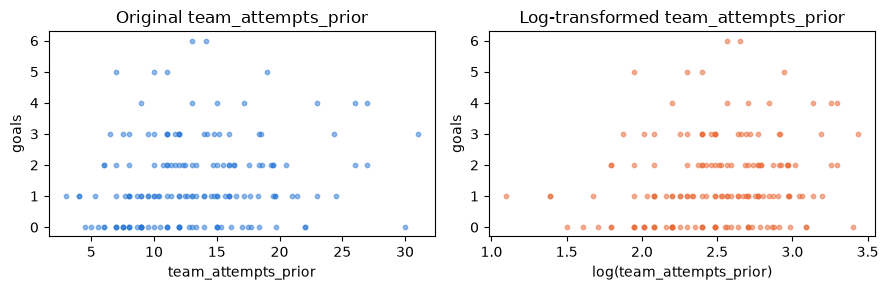

skew before 0.77, after -0.41


In [12]:
valid = T[T["team_attempts_prior"].notna()]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9, 3))
ax1.scatter(valid["team_attempts_prior"], valid["goals"], s=10, alpha=0.5, color=BLUE)
ax1.set(title="Original team_attempts_prior", xlabel="team_attempts_prior", ylabel="goals")
ax2.scatter(np.log(valid["team_attempts_prior"]), valid["goals"], s=10, alpha=0.5, color=ORANGE)
ax2.set(title="Log-transformed team_attempts_prior", xlabel="log(team_attempts_prior)", ylabel="goals")
plt.tight_layout(); plt.show()
print(f"skew before {valid['team_attempts_prior'].skew():.2f}, after {np.log(valid['team_attempts_prior']).skew():.2f}")

In [13]:
tips = [
    evaluate(T, feats, "no optimisation"),
    evaluate(T, feats, "tip 1 log(team_attempts_prior)", log_cols=["team_attempts_prior"]),
    evaluate(T, feats, "tip 3 z-score", tip="standardise"),
    evaluate(T, feats, "tip 4 Yeo-Johnson", tip="yeo-johnson"),
]
table(tips)

,statsmodels R2 (all rows),statsmodels adj R2,MAE,MSE,RMSE,NRMSE,test R2,baseline RMSE,baseline NRMSE
model,,,,,,,,,
no optimisation,0.310,0.282,0.817,1.069,1.034,0.148,0.204,1.159,0.166
tip 1 log(team_attempts_prior),0.309,0.281,0.815,1.071,1.035,0.148,0.202,1.159,0.166
tip 3 z-score,0.310,0.282,0.817,1.069,1.034,0.148,0.204,1.159,0.166
tip 4 Yeo-Johnson,0.314,0.287,0.803,1.041,1.020,0.146,0.225,1.159,0.166


## 9. strength vs form
each predictor group on its own.

In [14]:
strength = ["elo_diff", "team_log_value", "opp_log_value", "is_host"]
form = ["gf_prior_diff", "ga_prior_diff", "lb_prior_diff", "team_attempts_prior"]
table([evaluate(T, feats, "all 8 predictors"),
       evaluate(T, strength, "strength only (4)"),
       evaluate(T, form, "form only (4)")])

,statsmodels R2 (all rows),statsmodels adj R2,MAE,MSE,RMSE,NRMSE,test R2,baseline RMSE,baseline NRMSE
model,,,,,,,,,
all 8 predictors,0.310,0.282,0.817,1.069,1.034,0.148,0.204,1.159,0.166
strength only (4),0.290,0.276,0.823,1.139,1.067,0.152,0.152,1.159,0.166
form only (4),0.134,0.117,0.846,1.165,1.079,0.154,0.133,1.159,0.166


## 10. total vs average squad value
swap the value predictors; keep 8.

In [15]:
print("Pearson r with goals:  log total value", round(st.pearsonr(T["log_value"], T["goals"])[0], 3),
      "|  log average value", round(st.pearsonr(T["log_avg_value"], T["goals"])[0], 3))
T_avg = T.copy()
T_avg["team_log_value"], T_avg["opp_log_value"] = T_avg["log_avg_value"], T_avg["opp_log_avg_value"]
table([evaluate(T, feats, "total squad value"), evaluate(T_avg, feats, "average player value")])

Pearson r with goals:  log total value 0.416 |  log average value 0.408


,statsmodels R2 (all rows),statsmodels adj R2,MAE,MSE,RMSE,NRMSE,test R2,baseline RMSE,baseline NRMSE
model,,,,,,,,,
total squad value,0.310,0.282,0.817,1.069,1.034,0.148,0.204,1.159,0.166
average player value,0.307,0.279,0.807,1.046,1.023,0.146,0.221,1.159,0.166


## 11. summary figure, save outputs

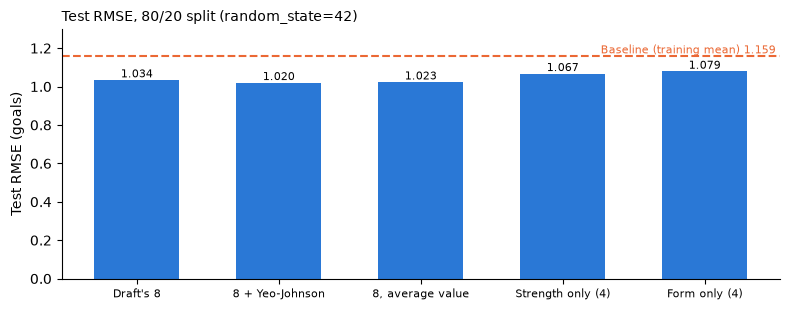

,statsmodels R2 (all rows),statsmodels adj R2,MAE,MSE,RMSE,NRMSE,test R2,baseline RMSE,baseline NRMSE
model,,,,,,,,,
Draft's 8,0.310,0.282,0.817,1.069,1.034,0.148,0.204,1.159,0.166
8 + Yeo-Johnson,0.314,0.287,0.803,1.041,1.020,0.146,0.225,1.159,0.166
"8, average value",0.307,0.279,0.807,1.046,1.023,0.146,0.221,1.159,0.166
Strength only (4),0.290,0.276,0.823,1.139,1.067,0.152,0.152,1.159,0.166
Form only (4),0.134,0.117,0.846,1.165,1.079,0.154,0.133,1.159,0.166


In [16]:
summary = table([evaluate(T, feats, "Draft's 8"),
                 evaluate(T, feats, "8 + Yeo-Johnson", tip="yeo-johnson"),
                 evaluate(T_avg, feats, "8, average value"),
                 evaluate(T, strength, "Strength only (4)"),
                 evaluate(T, form, "Form only (4)")])
fig, ax = plt.subplots(figsize=(8, 3.2))
bars = ax.bar(summary.index, summary["RMSE"], 0.6, color=BLUE)
for b in bars:
    ax.annotate(f"{b.get_height():.3f}", (b.get_x() + b.get_width() / 2, b.get_height()), ha="center", va="bottom", fontsize=8)
base = summary["baseline RMSE"].iloc[0]
ax.axhline(base, color=ORANGE, linestyle="--", linewidth=1.5)
ax.annotate(f"Baseline (training mean) {base:.3f}", (len(summary) - 0.5, base), ha="right", va="bottom", fontsize=8, color=ORANGE)
ax.set_ylabel("Test RMSE (goals)")
ax.set_ylim(0, base * 1.12)
ax.set_title(f"Test RMSE, 80/20 split (random_state={RANDOM_STATE})", fontsize=10, loc="left")
ax.tick_params(axis="x", labelsize=8)
for s in ["top", "right"]:
    ax.spines[s].set_visible(False)
plt.tight_layout()
plt.savefig(FIG / "rep_02_rmse_models.png", dpi=200)
plt.show()

summary.to_csv(OUT / "model_summary.csv")
T[["match", "team_name", "goals"] + feats].to_csv(OUT / "dataset_rebuilt.csv", index=False)
summary